In [25]:
import sys
sys.path.append("..")

In [26]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

In [27]:
df_ch_przeplyw = pd.read_parquet('../data/processed/Chorzów/przeplyw.parquet')
df_ch_scieki = pd.read_parquet('../data/processed/Chorzów/scieki.parquet')
df_ch_awarie = pd.read_parquet('../data/processed/Chorzów/awarie.parquet')
df_ch_energia = pd.read_parquet('../data/processed/Chorzów/energia.parquet')

In [29]:
#Alarmy 
alarm_cols = ["Awaria_pompy_P1", "Awaria_pompy_P2", "Awaria_pompy_P3", "Brak_wydajności_pompy_P1", "Brak_wydajnosci_pompy_P2", "Brak_wydajności_pompy_P3", "Spietrzenie"]

real_alarms = df_ch_awarie[df_ch_awarie[alarm_cols].eq("1.00").any(axis=1)].copy()
real_alarms = real_alarms.sort_values("Data_czas")

print("Liczba wpisów:", len(real_alarms))
print(real_alarms["Data_czas"].head(20))

Liczba wpisów: 195
413    2024-11-07 10:25:00
421    2024-11-07 12:22:00
423    2024-11-07 13:01:00
428    2024-11-07 13:34:00
561    2024-11-20 06:05:00
562    2024-11-20 06:20:00
564    2024-11-20 07:04:00
567    2024-11-20 07:05:00
570    2024-11-20 08:32:00
671    2024-11-28 07:54:00
998    2024-12-19 23:23:00
2797   2025-04-18 07:54:00
2799   2025-04-18 08:00:00
2824   2025-04-19 05:56:00
2830   2025-04-19 12:20:00
2856   2025-04-22 08:15:00
2858   2025-04-22 12:20:00
3117   2025-05-08 10:44:00
3118   2025-05-08 10:44:00
3119   2025-05-08 12:11:00
Name: Data_czas, dtype: datetime64[us]


In [30]:
alarm_dates = real_alarms["Data_czas"].drop_duplicates().sort_values()

# Nowy epizod, jeżeli od poprzedniego wpisu minęło ponad 30 minut
new_event = alarm_dates.diff() > pd.Timedelta("30min")
new_event.iloc[0] = True

event_dates = alarm_dates[new_event]

print("Wpisy alarmowe:", len(real_alarms))
print("Osobne epizody:", len(event_dates))

Wpisy alarmowe: 195
Osobne epizody: 161


In [31]:
alarm_dates = real_alarms["Data_czas"].drop_duplicates().sort_values()

In [32]:
#podział danych chronologicznie
#noo narazie to tak na oko, czasami może być właśnie tak, że ten podział 70:30 nie bedzie skuteczny
#najlepiej nauczyć model na takim zdrowym okresie

split = int(len(df)*0.7)

train = df.iloc[:split].copy()
test = df.iloc[split:].copy()

print(f"Train: {train.index.min()}, {train.index.max()}")
print(f"Test: {test.index.min()}, {test.index.max()}")

Train: 2024-10-11 20:34:20, 2026-03-01 11:33:35
Test: 2026-03-01 13:08:03, 2026-10-13 11:39:47


In [33]:
#MAD - mediana bezwzględnych odchyleń od mediany 
def mad(x):
    return np.median(np.abs(x-np.median(x)))

In [36]:
def evaluate(anomalies, event_dates, window="24h", grace="3h"):
    anomaly_dates = anomalies[anomalies].index
    window = pd.Timedelta(window)
    grace = pd.Timedelta(grace)

    TP = 0
    early = 0
    used = set()

    for event in event_dates:
        matches = [
            date for date in anomaly_dates
            if event - window <= date <= event + grace
            and date not in used
        ]

        if matches:
            date = matches[0]
            used.add(date)
            TP += 1

            if date <= event:
                early += 1

    FN = len(event_dates) - TP
    FP = len(anomaly_dates) - len(used)

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    beta = 1.8
    fbeta = (
        (1 + beta**2) * precision * recall /
        (beta**2 * precision + recall)
        if precision + recall else 0
    )

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "early": early,
        "precision": precision,
        "recall": recall,
        "F1.8": fbeta
    }

### IsolationForest
Algorytm uczenia nienadzorowanego, który służy do wykrywania anomalii, nietypowych zachowań (wykorzystuje losowe drzewa do izolowania nietypowych obserwacji -> umożliwia identyfikację nieprawidłowości z danych i wychodzi z założenia, że nietypowe obserwacje jest zazwyczaj łatwiej odizolować od pozostałych danych)

In [ ]:
df = df_ch_scieki.copy()

if "Data_czas" in df.columns:
    df["Data_czas"] = pd.to_datetime(df["Data_czas"])
    df = df.set_index("Data_czas")

df = df.rename(columns={
    "Przeplyw_chwilowy_cieczy": "przeplyw"
})

# konwersja na liczbowe
if df["ilosc"].dtype == 'object' or df["ilosc"].dtype == 'string':
    df["ilosc"] = df["ilosc"].astype(str).str.replace(',', '.')

df["ilosc"] = pd.to_numeric(df["przeplyw"], errors='coerce')


# usuwanie zer i śmieci
df = df[(df["przeplyw"].notna()) & (df["przeplyw"] != 0)]

df = df.sort_index()
print(df.head())

In [37]:
#isotree - ponieważ jest to bibliotrka z cpp, która zawiera ten wariant, a ten wariant jest odporny na ewentualne nany
#from isotree import IsolationForest 
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

In [38]:
df["diff"] = df["przeplyw"].diff()

#df["time_diff_h"] = df.index.to_series().diff().dt.total_seconds() / 3600

df["ewm"] = df["przeplyw"].ewm(span=12, adjust=False).mean()

In [39]:
features = ["przeplyw", "diff", "ewm"]

X = df[features].copy()
X = X.replace([np.inf, -np.inf], np.nan)

X_train = X.iloc[:split].copy()
X_test = X.iloc[split:].copy()

X_train = X_train.dropna(axis=1, how="all")
X_test = X_test[X.columns]

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

In [40]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

iso = IsolationForest(n_estimators=200, n_jobs=-1, random_state=42)

iso.fit(X_train_scaled)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [41]:
iso_scores_train = pd.Series(-iso.score_samples(X_train_scaled), index= X_train.index)
iso_scores_test = pd.Series(-iso.score_samples(X_test_scaled), index= X_test.index)


scores = pd.concat([iso_scores_train, iso_scores_test]).sort_index()

smooth_scores = scores.rolling("12h", min_periods=2).mean()

smooth_train = smooth_scores.reindex(iso_scores_train.index)
smooth_test = smooth_scores.reindex(iso_scores_test.index)

In [42]:
window = "7D"
k = 6
min_periods = 15

history = smooth_scores.rolling(window=window, min_periods=min_periods, closed="left")

median = history.median()
rolling_mad = history.apply(mad, raw=True)

# Dynamiczny próg
threshold_mad = median + k * 1.4826 * rolling_mad

# Wyniki wyłącznie dla test
threshold_test = threshold_mad.reindex(iso_scores_test.index)

anomalies_mad = iso_scores_test > threshold_test

print("Liczba anomalii:", anomalies_mad.sum())
print("Dostępne progi:", threshold_test.notna().sum())

Liczba anomalii: 170
Dostępne progi: 1184


In [43]:
alarm_dates = real_alarms["Data_czas"].drop_duplicates().sort_values()

new_event = alarm_dates.diff() > pd.Timedelta("3h")
new_event.iloc[0] = True

event_dates = alarm_dates[new_event]

metrics = evaluate(anomalies_mad, event_dates, window="7days", grace="3h")
print(metrics)

{'TP': 47, 'FP': 123, 'FN': 80, 'early': 46, 'precision': 0.27647058823529413, 'recall': 0.3700787401574803, 'F1.8': 0.3427117011763088}


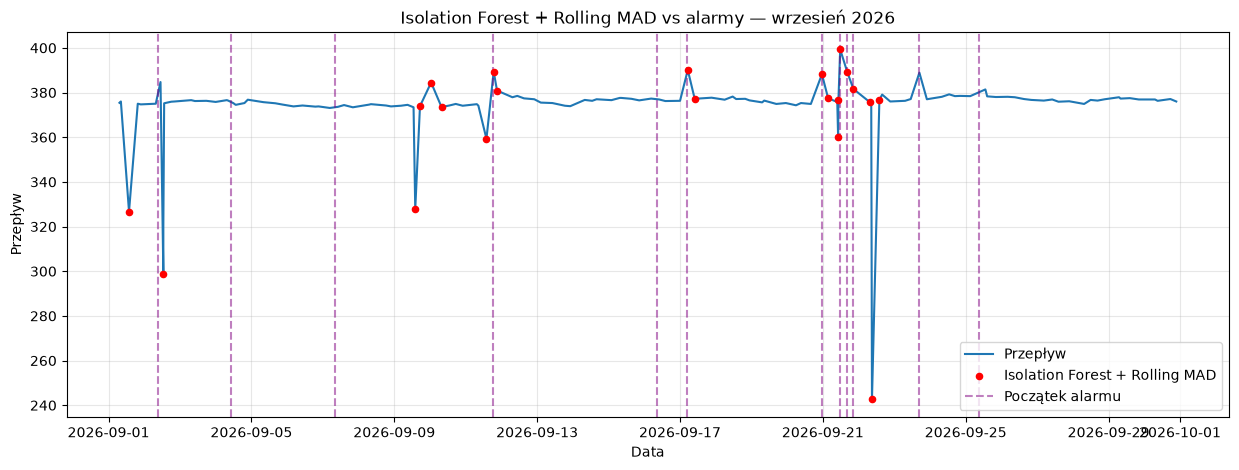

In [44]:
start = "2026-09-01"
end = "2026-10-01"

test_month = test.loc[
    (test.index >= start) & (test.index < end)
].copy()

# Dodajemy wyniki Isolation Forest + Rolling MAD
test_month["anomaly_mad"] = anomalies_mad.reindex(
    test_month.index, fill_value=False
)

# Początki epizodów alarmowych
alarms_month = event_dates[
    (event_dates >= start) &
    (event_dates < end)
]

plt.figure(figsize=(15, 5))

plt.plot(
    test_month.index,
    test_month["przeplyw"],
    label="Przepływ"
)

# Anomalie Isolation Forest + Rolling MAD
detected = test_month[test_month["anomaly_mad"]]

plt.scatter(
    detected.index,
    detected["przeplyw"],
    color="red",
    s=20,
    label="Isolation Forest + Rolling MAD",
    zorder=3
)

# Początki epizodów alarmowych
for i, date in enumerate(alarms_month):
    plt.axvline(
        date,
        color="purple",
        linestyle="--",
        alpha=0.5,
        label="Początek alarmu" if i == 0 else None
    )

plt.title("Isolation Forest + Rolling MAD vs alarmy — wrzesień 2026")
plt.xlabel("Data")
plt.ylabel("Przepływ")
plt.legend()
plt.grid(alpha=0.3)
plt.show()